In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

BASE = "/content/drive/MyDrive/Noshows"
DATA, MODELS, REPORTS = BASE + "/data", BASE + "/models", BASE + "/reports"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load the files from US06

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X_train = pd.read_csv(DATA + "/X_train_scaled.csv")
X_test  = pd.read_csv(DATA + "/X_test_scaled.csv")
y_train = pd.read_csv(DATA + "/y_train.csv").squeeze()
y_test  = pd.read_csv(DATA + "/y_test.csv").squeeze()

Define the 4 algorithms

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}

Train and measure each one

In [ ]:
text_cols = X_train.select_dtypes("object").columns.tolist()
print("Removed:", text_cols)

Removed: ['Non-présentation']


In [ ]:
X_train = X_train.drop(columns=text_cols)
X_test  = X_test.drop(columns=text_cols)

In [ ]:
assert X_train.select_dtypes("object").empty, "Text columns remain!"
print("no_show inside X?", "no_show" in X_train.columns)                    # must be False
print("Same columns in train and test?", X_train.columns.tolist() == X_test.columns.tolist())  # True
print(X_train.shape)

no_show inside X? False
Same columns in train and test? True
(88412, 97)


In [ ]:
cols = X_train.columns.tolist()
print(len(cols))
print([c for c in cols if not c.startswith("Quartier")])
print(sum(c.startswith("Quartier") for c in cols), "neighborhood columns")

97
['Age', 'Bourse', 'SMS_reçu', 'Radio dentaire réalisée', 'Genre_M', 'Nom du dentiste_Dr. Hamza Idrissi', 'Nom du dentiste_Dr. Lina Tazi', 'Nom du dentiste_Dr. Mehdi Alaoui', 'Nom du dentiste_Dr. Meryem Fassi', 'Nom du dentiste_Dr. Nour El Khatib', 'Nom du dentiste_Dr. Omar Berrada', 'Nom du dentiste_Dr. Salma Bennani', 'Nom du dentiste_Dr. Sara Chraibi', 'Nom du dentiste_Dr. Yassine El Amrani', 'WaitingDays', 'Weekday', 'Délai réservation']
80 neighborhood columns


In [ ]:
neigh = [c for c in X_train.columns if c.startswith("Quartier")]
X_train = X_train.drop(columns=neigh)
X_test  = X_test.drop(columns=neigh)
print(X_train.shape)

(88412, 17)


find  x_train


In [ ]:
na_train = X_train.isna().sum()
na_test  = X_test.isna().sum()
print("In train:\n", na_train[na_train > 0])
print("In test:\n",  na_test[na_test > 0])
print("Rows with NaN in train:", X_train.isna().any(axis=1).sum(), "of", len(X_train))

In train:
 Radio dentaire réalisée    88412
dtype: int64
In test:
 Radio dentaire réalisée    22103
dtype: int64
Rows with NaN in train: 88412 of 88412


In [ ]:

drop_cols = ["Radio dentaire réalisée"] + [c for c in X_train.columns if c.startswith("Quartier")]
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_test  = X_test.drop(columns=drop_cols, errors="ignore")


na = X_train.isna().sum()
print("Remaining NaN columns:", na[na > 0].to_dict())
print("Same columns in train and test?", X_train.columns.tolist() == X_test.columns.tolist())
print(X_train.shape)
print(X_train.columns.tolist())

Remaining NaN columns: {}
Same columns in train and test? True
(88412, 16)
['Age', 'Bourse', 'SMS_reçu', 'Genre_M', 'Nom du dentiste_Dr. Hamza Idrissi', 'Nom du dentiste_Dr. Lina Tazi', 'Nom du dentiste_Dr. Mehdi Alaoui', 'Nom du dentiste_Dr. Meryem Fassi', 'Nom du dentiste_Dr. Nour El Khatib', 'Nom du dentiste_Dr. Omar Berrada', 'Nom du dentiste_Dr. Salma Bennani', 'Nom du dentiste_Dr. Sara Chraibi', 'Nom du dentiste_Dr. Yassine El Amrani', 'WaitingDays', 'Weekday', 'Délai réservation']


In [ ]:
drop_cols = (["Radio dentaire réalisée", "Délai réservation"]
             + [c for c in X_train.columns if c.startswith("Quartier")])
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_test  = X_test.drop(columns=drop_cols, errors="ignore")

print(X_train.shape)

(88412, 15)


Save the table and pick the winner

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, os
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

BASE = "/content/drive/MyDrive/Noshows"
DATA, REPORTS = BASE + "/data", BASE + "/reports"
os.makedirs(REPORTS + "/figures", exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
X_train = pd.read_csv(DATA + "/X_train_scaled.csv")
X_test  = pd.read_csv(DATA + "/X_test_scaled.csv")
y_train = pd.read_csv(DATA + "/y_train.csv").squeeze()
y_test  = pd.read_csv(DATA + "/y_test.csv").squeeze()

In [ ]:
drop_cols = (["Délai réservation"]
             + [c for c in X_train.columns if c.startswith("Quartier")])
if X_train["Radio dentaire réalisée"].isna().all():
    drop_cols.append("Radio dentaire réalisée")
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_test  = X_test.drop(columns=drop_cols, errors="ignore")

In [ ]:
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "NaN found: rerun US05 and US06"
assert X_train.select_dtypes(include=["object", "string"]).empty, "Text found: rerun US05 and US06"
assert "no_show" not in X_train.columns
assert X_train.columns.tolist() == X_test.columns.tolist()
print("Predictors:", X_train.shape[1], "|", X_train.shape)

Predictors: 15 | (88412, 15)


In [ ]:

text_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
print("Text columns removed:", text_cols)

drop_cols = (text_cols + ["Délai réservation"]
             + [c for c in X_train.columns if c.startswith("Quartier")])
if "Radio dentaire réalisée" in X_train.columns and X_train["Radio dentaire réalisée"].isna().all():
    drop_cols.append("Radio dentaire réalisée")

X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_test  = X_test.drop(columns=drop_cols, errors="ignore")

Text columns removed: ['Non-présentation']


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}

In [ ]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Algorithm": name,
                 "Accuracy":  accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall":    recall_score(y_test, pred),
                 "F1":        f1_score(y_test, pred)})
    print(name, "done")

results = pd.DataFrame(rows).round(3).sort_values("F1", ascending=False)

Logistic Regression done
Decision Tree done
Random Forest done
KNN done


save the table and the chart

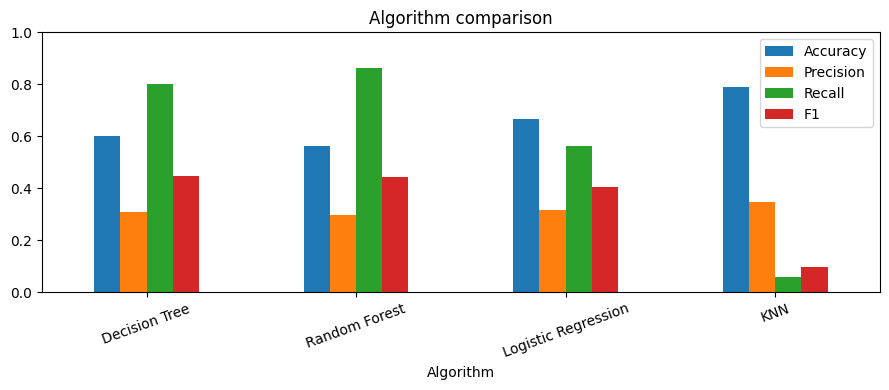

Best algorithm: Decision Tree | Recall: 0.802 | F1: 0.447


,Algorithm,Accuracy,Precision,Recall,F1
1,Decision Tree,0.599,0.310,0.802,0.447
2,Random Forest,0.562,0.298,0.863,0.443
0,Logistic Regression,0.665,0.315,0.562,0.404
3,KNN,0.788,0.345,0.057,0.098


In [ ]:
results.to_csv(REPORTS + "/comparaison_algorithmes.csv", index=False)
results.set_index("Algorithm")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(9, 4), title="Algorithm comparison")
plt.xticks(rotation=20); plt.ylim(0, 1); plt.tight_layout()
plt.savefig(REPORTS + "/figures/comparaison_algorithmes.png", dpi=150)
plt.show()

best = results.iloc[0]
print("Best algorithm:", best["Algorithm"], "| Recall:", best["Recall"], "| F1:", best["F1"])
results